# Chapter 6 — Fine-tuning for Text Classification

## 1. Mục tiêu Chapter 6

Chapter 6 trong sách *Build a Large Language Model (From Scratch)* của Sebastian Raschka hướng dẫn cách **Fine-tune GPT đã được Pretrain để phân loại văn bản**.

Ví dụ:
- Input: `"You won $1000"` → Output: `Spam (1)`
- Input: `"See you tomorrow"` → Output: `Not Spam (0)`

**Quy trình tổng quát:**

`Pretrained GPT → Dataset → Tokenization → Classification Head → Fine-tuning → Evaluation → Prediction`

---

## 2. Pretraining vs Fine-tuning

### Pretraining
- Huấn luyện GPT từ đầu trên lượng lớn văn bản.
- Nhiệm vụ: **Next-token Prediction**.
- Mục tiêu: Học các quy luật và biểu diễn ngôn ngữ.

Ví dụ:
- Input: `"I love machine"`
- Target: `"learning"`

### Fine-tuning
- Sử dụng mô hình đã được Pretrain.
- Tiếp tục huấn luyện trên dữ liệu của một nhiệm vụ cụ thể.
- Không cần train lại toàn bộ mô hình từ đầu.

Ví dụ:
- Input: `"Congratulations! You won $1000"`
- Target: `Spam (1)`

**Cần nhớ:** Pretraining giúp GPT học ngôn ngữ, Fine-tuning giúp GPT thực hiện nhiệm vụ cụ thể.

---

## 3. Classification Fine-tuning

Text Classification là nhiệm vụ phân loại văn bản vào các nhãn xác định.

Ví dụ:
- `0`: Ham (Not Spam)
- `1`: Spam

GPT ban đầu dự đoán token tiếp theo. Để phân loại văn bản, ta thay **Language Modeling Head** bằng **Classification Head**.

---

## 4. Classification Head

GPT-2 Small có:
- Embedding dimension: `768`
- Vocabulary size: `50,257`

**Trước Fine-tuning:**

`Hidden States (768) → Linear(768, 50257) → Token Logits`

**Sau khi thay Classification Head:**

`Hidden States (768) → Linear(768, 2) → Class Logits`

Code:

```python
model.out_head = torch.nn.Linear(768, 2)
```

Trong đó:
- `768`: Số chiều hidden state.
- `2`: Số class cần phân loại.
- Classification Head mới cần được huấn luyện.

**Cần nhớ:** Classification Head chuyển biểu diễn của GPT thành điểm số cho các nhãn phân loại.

---

## 5. Tại sao lấy Hidden State của token cuối?

GPT sử dụng **Causal Self-Attention**:
- Mỗi token chỉ nhìn thấy chính nó và các token phía trước.
- Token cuối có thể tổng hợp thông tin từ toàn bộ các token trước đó.

Ví dụ:

`"You" → "won" → "a" → "prize"`

Token `"prize"` có thể chú ý đến cả chuỗi.

Output của GPT sau khi thay head:

```python
logits = model(input_ids)
# Shape: (batch_size, seq_len, 2)

class_logits = logits[:, -1, :]
# Shape: (batch_size, 2)
```

Giải thích:
- `:`: Lấy toàn bộ batch.
- `-1`: Lấy vị trí token cuối.
- `:`: Lấy logits của tất cả class.

**Cần nhớ:** Lấy vị trí cuối vì nó có thể chứa thông tin từ toàn bộ chuỗi trước đó. Nếu có padding cuối chuỗi, vị trí này có thể là padding; sách vẫn huấn luyện theo cách lấy vị trí cuối cố định.


Hidden State là gì?
Hidden State là một vector chứa các đặc trưng mà mô hình học được về một token sau khi xử lý qua các layer của Neural Network.

Nói đơn giản:
- Token ID: Cho biết token nào đang được đưa vào.
- Embedding: Biến token thành vector số ban đầu.
- Hidden State: Vector đã được Transformer xử lý, kết hợp thêm thông tin ngữ cảnh.
- Output Head: Sử dụng hidden state để dự đoán token hoặc phân loại văn bản.

---

## 6. Freeze vs Unfreeze Layers

### Freeze
Giữ nguyên trọng số, không cập nhật khi training.

```python
for param in model.parameters():
    param.requires_grad = False
```

### Unfreeze
Cho phép trọng số được cập nhật thông qua Backpropagation.

Trong Chapter 6, tác giả huấn luyện:
- Classification Head mới.
- Transformer Block cuối.
- Final Normalization Layer.

```python
model.out_head = torch.nn.Linear(768, 2)

for param in model.trf_blocks[-1].parameters():
    param.requires_grad = True

for param in model.final_norm.parameters():
    param.requires_grad = True
```

**Tại sao Freeze?**
- Giữ lại kiến thức đã học từ Pretraining.
- Giảm số tham số cần huấn luyện.
- Tiết kiệm tài nguyên tính toán.

**Cần nhớ:** Freeze = không cập nhật trọng số; Unfreeze = cho phép cập nhật trọng số.

---

## 7. Dataset Preparation

Fine-tuning cho classification cần dữ liệu có nhãn.

Ví dụ:

| Text | Label |
|---|---|
| You won a prize | 1 |
| See you tomorrow | 0 |
| Claim your reward | 1 |
| Are you free tonight? | 0 |

Các bước chuẩn bị:

1. Load Dataset.
2. Kiểm tra và xử lý dữ liệu.
3. Cân bằng class nếu cần.
4. Chia Train / Validation / Test.
5. Tokenization.
6. Padding / Truncation.
7. Tạo Dataset và DataLoader.

### Khái niệm cần nhớ

- **Tokenization:** Chuyển văn bản thành Token IDs.
- **Padding:** Thêm token để các chuỗi có cùng độ dài.
- **Truncation:** Cắt bớt chuỗi quá dài.
- **Dataset:** Quản lý các mẫu dữ liệu.
- **DataLoader:** Chia dữ liệu thành mini-batches.
- **Train Set:** Dùng để cập nhật trọng số.
- **Validation Set:** Theo dõi quá trình học và chọn cấu hình.
- **Test Set:** Đánh giá cuối cùng trên dữ liệu chưa thấy.

---

## 8. Cross-Entropy Loss

Cross-Entropy đo mức sai giữa dự đoán của mô hình và nhãn thực tế.

Ví dụ:

- `P(Ham) = 0.1`
- `P(Spam) = 0.9`
- Nhãn thực tế: `Spam`

Công thức:

`Loss = -log(P(class đúng))`

Kết quả:

`Loss = -log(0.9) ≈ 0.105`

Nếu mô hình dự đoán sai với độ tự tin cao, Loss sẽ lớn.

Code:

```python
loss = torch.nn.functional.cross_entropy(
    class_logits,
    labels
)
```

**Lưu ý:** Không cần gọi `softmax()` trước `cross_entropy()` vì hàm này nhận logits và đã xử lý phép chuẩn hóa cần thiết.

**Khác Chapter 5:**
- Chapter 5: Cross-Entropy trên token tiếp theo.
- Chapter 6: Cross-Entropy trên nhãn phân loại.

1. Gradient là gì?
Gradient cho biết khi thay đổi trọng số của mô hình thì Loss thay đổi như thế nào.

Ví dụ mô hình dự đoán Spam:
- Nhãn đúng: Spam (1).
- Mô hình dự đoán sai.
- Cross-Entropy tính ra Loss.
- Gradient giúp xác định nên điều chỉnh trọng số theo hướng nào để giảm Loss.
Công thức cập nhật trọng số đơn giản của Gradient Descent:
$$
w_{\text{new}}=w_{\text{old}}-\eta\frac{\partial L}{\partial w}
$$

Trong đó:
- \(w\): Trọng số của mô hình.
- \(L\): Loss.
- \(\eta\): Learning rate.
- \(\frac{\partial L}{\partial w}\): Gradient của Loss theo trọng số.
- 
Nếu gradient âm, bước Gradient Descent sẽ tăng trọng số. Nếu gradient dương, bước đó sẽ giảm trọng số.



4. Khi nào bật và khi nào tắt?
Trường hợp	Nên làm
Train mô hình từ đầu	Bật grad cho tham số cần học
Full fine-tuning	Bật grad cho toàn bộ tham số cần cập nhật
Partial fine-tuning	Freeze các layer không muốn cập nhật
Validation	Dùng torch.no_grad()
Test / Inference	Dùng torch.no_grad() hoặc torch.inference_mode()
Chỉ tính Accuracy	Không cần gradient

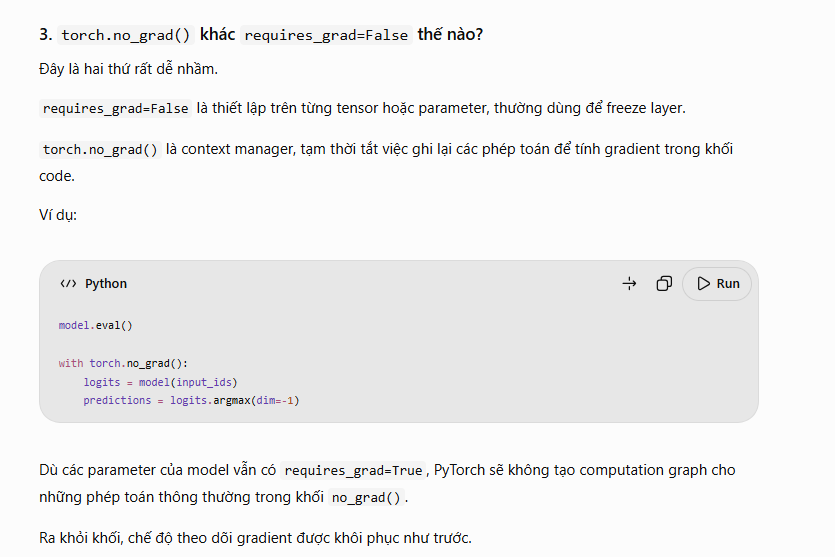

---

## 9. Training Loop

Quy trình:

`Input → Forward → Loss → Backward → Optimizer → Repeat`

Code:

```python
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=5e-5
)

model.train()

for input_ids, labels in train_loader:
    optimizer.zero_grad()

    logits = model(input_ids)
    class_logits = logits[:, -1, :]

    loss = torch.nn.functional.cross_entropy(
        class_logits,
        labels
    )

    loss.backward()
    optimizer.step()
```

### Các hàm quan trọng

| Hàm | Chức năng |
|---|---|
| `model(input_ids)` | Forward Pass |
| `cross_entropy()` | Tính Loss |
| `zero_grad()` | Xóa Gradient cũ |
| `backward()` | Tính Gradient |
| `step()` | Cập nhật trọng số |
| `model.train()` | Chuyển sang chế độ Training |
| `model.eval()` | Chuyển sang chế độ Evaluation |
| `torch.no_grad()` | Tắt tính Gradient khi đánh giá |

**Cần nhớ:** Backward tính Gradient, Optimizer sử dụng Gradient để cập nhật trọng số.

---

## 10. Evaluation

Sau Fine-tuning, cần đánh giá trên dữ liệu chưa dùng để huấn luyện.

### Các Metrics

- **Accuracy:** Tỷ lệ dự đoán đúng.
- **Precision:** Trong các mẫu dự đoán Spam, bao nhiêu mẫu thực sự Spam?
- **Recall:** Trong các mẫu Spam thực tế, phát hiện được bao nhiêu?
- **F1-score:** Trung bình điều hòa Precision và Recall.
- **Validation Loss:** Đánh giá mức sai trên tập Validation.

Trong sách, tác giả tập trung chủ yếu vào Loss và Accuracy.

### Overfitting

- Train Loss giảm.
- Validation Loss tăng.

Điều này có thể cho thấy mô hình đang học quá sát Training Data và tổng quát hóa kém.

---

## 11. Inference — Dự đoán văn bản mới

Sau Fine-tuning:

1. Nhận văn bản mới.
2. Tokenize và Padding.
3. Đưa vào GPT.
4. Lấy Class Logits ở vị trí cuối.
5. Dùng `argmax()` chọn class có logit lớn nhất.

```python
model.eval()

with torch.no_grad():
    logits = model(input_ids)
    class_logits = logits[:, -1, :]
    predictions = torch.argmax(
        class_logits,
        dim=-1
    )
```

Ví dụ:

`"You won a free iPhone!" → Spam (1)`

---

## 12. Kiến thức bắt buộc phải nắm

- [ ] Phân biệt Pretraining và Fine-tuning.
- [ ] Hiểu Classification Fine-tuning.
- [ ] Hiểu tại sao phải thay Classification Head.
- [ ] Hiểu `Linear(768, 2)`.
- [ ] Hiểu vì sao sử dụng vị trí token cuối.
- [ ] Hiểu Freeze và Unfreeze Layers.
- [ ] Biết chuẩn bị Dataset, Tokenization, Padding.
- [ ] Hiểu Cross-Entropy cho Classification.
- [ ] Hiểu Training Loop và Backpropagation.
- [ ] Biết sử dụng AdamW Optimizer.
- [ ] Biết đánh giá Loss, Accuracy và F1-score.
- [ ] Biết thực hiện Inference trên dữ liệu mới.

---

## 13. Practice

**Bài thực hành:** Fine-tune GPT-2 Small để phân loại SMS Spam.

Các bước:

1. Load SMS Spam Collection Dataset.
2. Cân bằng dữ liệu và chia Train / Validation / Test.
3. Tokenize và tạo DataLoader.
4. Load Pretrained GPT-2.
5. Thay Output Head bằng Classification Head.
6. Freeze và Unfreeze các Layer cần thiết.
7. Fine-tune bằng Cross-Entropy và AdamW.
8. Theo dõi Training Loss, Validation Loss và Accuracy.
9. Đánh giá mô hình trên Test Set.
10. Dự đoán tin nhắn mới.

**Source Code:**
https://github.com/rasbt/LLMs-from-scratch/tree/main/ch06

---

## 14. Tổng kết Chapter 6

**Bản chất của Chapter 6:**

GPT đã học ngôn ngữ qua Pretraining. Ta tận dụng các trọng số đó, thay Output Head để dự đoán nhãn phân loại, rồi Fine-tune những Layer cần thiết bằng dữ liệu có nhãn.

**Công thức ghi nhớ:**

`Pretrained GPT → Classification Head → Cross-Entropy → Backpropagation → Updated Weights → Class Prediction`

**5 điều quan trọng nhất:**

1. **Fine-tuning:** Tận dụng mô hình đã Pretrain cho nhiệm vụ cụ thể.
2. **Classification Head:** Chuyển Hidden States thành Class Logits.
3. **Freeze / Unfreeze:** Quyết định những trọng số nào được cập nhật.
4. **Cross-Entropy:** Đo sai số dự đoán nhãn.
5. **Training Loop:** Cập nhật trọng số để mô hình phân loại tốt hơn.

**Kết quả cần đạt:** Có thể tự giải thích và triển khai quá trình biến một GPT Pretrained thành mô hình Text Classification bằng PyTorch.
